### Importing Libraries

In [1]:
# import os
# os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

GPU Usage?

In [2]:
import tensorflow as tf

if tf.config.list_physical_devices('GPU'):
    print("TensorFlow is using the GPU!")

    gpus = tf.config.list_physical_devices('GPU')
    print("Available GPUs:", gpus)

    for gpu in gpus:
        details = tf.config.experimental.get_device_details(gpu)
        print("GPU Details:", details)
else:
    print("TensorFlow is using the CPU.")

TensorFlow is using the GPU!
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU Details: {'device_name': 'NVIDIA GeForce RTX 3050 Laptop GPU', 'compute_capability': (8, 6)}


In [3]:
import os
import tensorflow as tf
from tensorflow.keras.models import load_model

class ClassBalancedFocalLoss(tf.keras.losses.Loss):
    # LABELS: 1=PNEUMONIA, 0=NORMAL
    
    def __init__(self, alpha=0.25, gamma=2.0, name="focal_loss", **kwargs):
        super().__init__(name=name, **kwargs)
        self.alpha = alpha
        self.gamma = gamma

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, tf.keras.backend.epsilon(), 1 - tf.keras.backend.epsilon())
        cross_entropy = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)
        p_t = y_true * y_pred + (1 - y_true) * (1 - y_pred)
        alpha_t = y_true * self.alpha + (1 - y_true) * (1 - self.alpha)
        loss = alpha_t * tf.math.pow((1 - p_t), self.gamma) * cross_entropy
        return tf.reduce_mean(loss)

    def get_config(self):
        config = super().get_config()
        config.update({
            "alpha": self.alpha,
            "gamma": self.gamma,
        })
        return config


class AdaMed(tf.keras.optimizers.Optimizer):
    def __init__(self, learning_rate=0.001, beta_1=0.9, beta_2=0.999, gamma_align=0.1, weight_decay=1e-4, epsilon=1e-7, name="AdaMed", **kwargs):
        super().__init__(name=name, **kwargs)
        self._set_hyper("learning_rate", kwargs.get("lr", learning_rate))
        self.beta_1 = beta_1
        self.beta_2 = beta_2
        self.gamma_align = gamma_align
        self.weight_decay = weight_decay
        self.epsilon = epsilon
        
    def _create_slots(self, var_list):
        for var in var_list:
            self.add_slot(var, "m")
            self.add_slot(var, "v")
            
    def _resource_apply_dense(self, grad, var, apply_state=None):
        m = self.get_slot(var, "m")
        v = self.get_slot(var, "v")
        lr = self._get_hyper("learning_rate")
        
        dot_product = tf.reduce_sum(grad * m)
        norm_g = tf.norm(grad)
        norm_m = tf.norm(m)
        rho_t = tf.clip_by_value(dot_product / (norm_g * norm_m + self.epsilon), 0.0, 1.0)
        
        m_t = self.beta_1 * m + (1.0 - self.beta_1) * (1.0 + self.gamma_align * rho_t) * grad
        v_t = self.beta_2 * v + (1.0 - self.beta_2) * tf.square(grad)
        
        wd = self.weight_decay * (2.0 - rho_t)
        var_t = var - lr * (m_t / (tf.sqrt(v_t) + self.epsilon) + wd * var)
        
        from tensorflow.keras import backend as K
        m_update = K.update(m, m_t)
        v_update = K.update(v, v_t)
        var_update = K.update(var, var_t)
        return tf.group(m_update, v_update, var_update)
        
    def get_config(self):
        config = super().get_config()
        config.update({
            "learning_rate": self._serialize_hyperparameter("learning_rate"),
            "beta_1": self.beta_1, "beta_2": self.beta_2, "gamma_align": self.gamma_align,
            "weight_decay": self.weight_decay, "epsilon": self.epsilon,
        })
        return config


H5_DIR = r"C:\CODES__SSD512\Minor_Major_Pneumonia\Major\H5"
MINOR_H5_DIR = r"C:\CODES__SSD512\Minor_Major_Pneumonia\Minor\H5"

LEGACY_MODEL_PATH = os.path.join(H5_DIR, "custom_E27_CLAHE_Contrast_Xception_P4I3A3M7T4.keras")
if not os.path.exists(LEGACY_MODEL_PATH):
    LEGACY_MODEL_PATH = os.path.join(MINOR_H5_DIR, "E27_CLAHE_Contrast_Xception_P4I3A3M7T4.keras")
    
MODEL_PATH = os.path.join(H5_DIR, "custom_E27_CLAHE_Contrast_Xception_P4I3A3M7T4_L1PNEU.keras")

In [4]:
import os
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Conv2D, MaxPool2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint


GLOBAL_SEED = 123
os.environ["PYTHONHASHSEED"] = str(GLOBAL_SEED)
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
tf.keras.utils.set_random_seed(GLOBAL_SEED)


# Pneumonia Data___Set


In [5]:

LABEL_MAP    = {'NORMAL': 0, 'PNEUMONIA': 1}          # folder name -> integer label
CLASS_NAMES  = ['NORMAL', 'PNEUMONIA']                # integer label -> name (index == label)
POS_LABEL    = 1                                      # PNEUMONIA is the positive class
FOLDER_ORDER = ['PNEUMONIA', 'NORMAL']                # iteration order kept identical to the old notebook
img_resize = 224

def get_data(dir):
    data = []
    
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    
    for label in FOLDER_ORDER:
        path = os.path.join(dir, label)
        class_num = LABEL_MAP[label]  # LABELS: 1=PNEUMONIA, 0=NORMAL

        for img in os.listdir(path):
            try:
                if img.lower().endswith(('.jpeg', '.jpg', '.png')):
                    img_path = os.path.join(path, img)

                    # grayscale
                    img_arr = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

                    if img_arr is None:
                        continue

                    # Resize
                    resized_arr = cv2.resize(img_arr, (img_resize, img_resize))

                    #CLAHE
                    clahe_img = clahe.apply(resized_arr)

                    # Contrast enhancement
                    contrast_img = cv2.convertScaleAbs(clahe_img, alpha=1.2, beta=0)

                    #  Convert to 3-channel
                    rgb_arr = cv2.cvtColor(contrast_img, cv2.COLOR_GRAY2RGB)

                    data.append([rgb_arr, class_num, img])  

            except Exception as e:
                print(f"Error loading image {img}: {e}")

    return np.array(data, dtype='object')

In [6]:
train = get_data(r"C:\CODES__SSD512\Minor_Major_Pneumonia\Major\ChestXRay2017\chest_xray\train")
val   = get_data(r"C:\CODES__SSD512\Minor_Major_Pneumonia\Major\ChestXRay2017\chest_xray\val")
test  = get_data(r"C:\CODES__SSD512\Minor_Major_Pneumonia\Major\ChestXRay2017\chest_xray\test")

In [7]:

for name, ds in [('train', train), ('val', val), ('test', test)]:
    y = np.array([int(s[1]) for s in ds])
    counts = np.bincount(y, minlength=2)
    print(f"{name}: NORMAL(0)={counts[0]}  PNEUMONIA(1)={counts[1]}")
    assert counts[1] > 0 and counts[0] > 0



train: NORMAL(0)=1318  PNEUMONIA(1)=3852
val: NORMAL(0)=31  PNEUMONIA(1)=31
test: NORMAL(0)=234  PNEUMONIA(1)=390


In [8]:
def count_images(dataset, name):
    pneumonia = 0
    normal = 0

    for i in dataset:
        if i[1] == LABEL_MAP['PNEUMONIA']:  # LABELS: 1=PNEUMONIA, 0=NORMAL
            pneumonia += 1
        else:
            normal += 1

    total = pneumonia + normal

    print(f"\n{name} DATASET:")
    print("Total images:", total)
    print("PNEUMONIA images:", pneumonia)
    print("NORMAL images:", normal)


count_images(train, "TRAIN")
count_images(val, "VALIDATION")
count_images(test, "TEST")



TRAIN DATASET:
Total images: 5170
PNEUMONIA images: 3852
NORMAL images: 1318

VALIDATION DATASET:
Total images: 62
PNEUMONIA images: 31
NORMAL images: 31

TEST DATASET:
Total images: 624
PNEUMONIA images: 390
NORMAL images: 234


## Data Visualization && Preprocessing

<Axes: xlabel='count'>

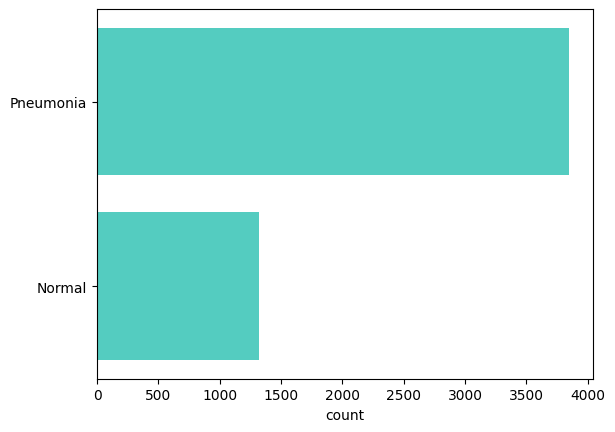

In [9]:
l = []
for i in train:
    l.append(CLASS_NAMES[int(i[1])].capitalize())  # LABELS: 1=PNEUMONIA, 0=NORMAL

sns.countplot(y=l, color='#40E0D0')


Text(0.5, 1.0, 'NORMAL')

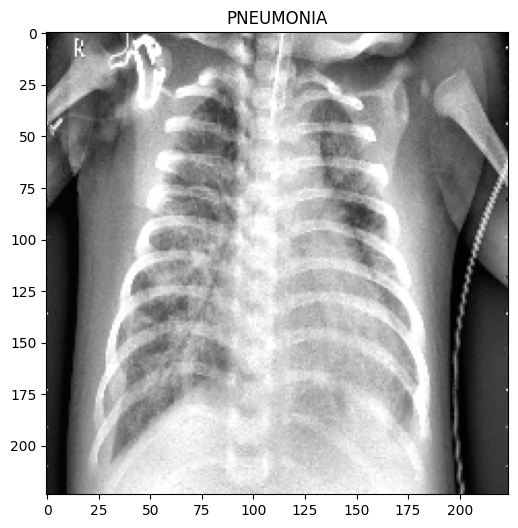

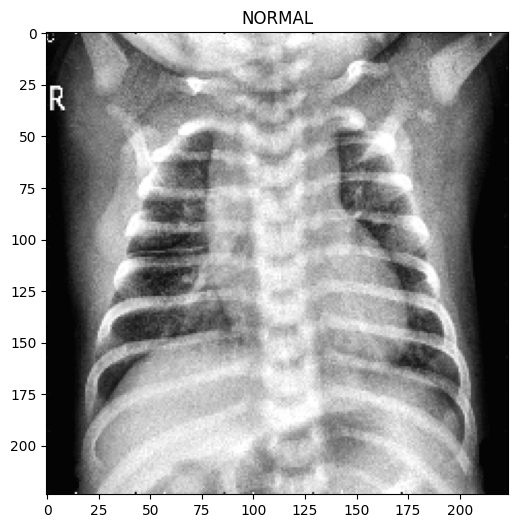

In [10]:
plt.figure(figsize=(6,6))
plt.imshow(train[0][0], cmap='gray')
plt.title(CLASS_NAMES[train[0][1]])  # LABELS: 1=PNEUMONIA, 0=NORMAL

plt.figure(figsize=(6,6))
plt.imshow(train[-11][0], cmap='gray')
plt.title(CLASS_NAMES[train[-11][1]])  # LABELS: 1=PNEUMONIA, 0=NORMAL


In [11]:

x_train = np.stack([s[0] for s in train]).astype('uint8'); y_train = np.array([int(s[1]) for s in train])
x_val   = np.stack([s[0] for s in val]).astype('uint8');   y_val   = np.array([int(s[1]) for s in val])
x_test  = np.stack([s[0] for s in test]).astype('uint8');  y_test  = np.array([int(s[1]) for s in test])
n_train = np.array([s[2] for s in train]); n_val = np.array([s[2] for s in val]); n_test = np.array([s[2] for s in test])

import gc
del train, val, test
gc.collect()


PROTOCOL = "patient_resplit"
SPLIT_SEED = 42

import re
def patient_id(fname, label):
    m = re.match(r'(person\d+)_', fname)                     
    if m:
        return m.group(1)
    return re.sub(r'-\d+\.(jpe?g|png)$', '', fname, flags=re.I)  

if PROTOCOL == "patient_resplit":
    x_all = np.concatenate([x_train, x_val, x_test]); y_all = np.concatenate([y_train, y_val, y_test])
    n_all = np.concatenate([n_train, n_val, n_test])
    del x_train, x_val, x_test; gc.collect()
    groups = np.array([patient_id(f, y) for f, y in zip(n_all, y_all)])
    try:
        from sklearn.model_selection import StratifiedGroupKFold
        folds = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SPLIT_SEED).split(n_all, y_all, groups))
    except ImportError:   # older scikit-learn
        from sklearn.model_selection import GroupKFold
        folds = list(GroupKFold(n_splits=10).split(n_all, y_all, groups))
    test_idx, val_idx = folds[0][1], folds[1][1]
    train_idx = np.setdiff1d(np.arange(len(y_all)), np.concatenate([test_idx, val_idx]))
    assert not (set(groups[train_idx]) & set(groups[test_idx])) and not (set(groups[train_idx]) & set(groups[val_idx]))
    assert not (set(groups[val_idx]) & set(groups[test_idx]))
    x_train, y_train = x_all[train_idx], y_all[train_idx]
    x_val,   y_val   = x_all[val_idx],   y_all[val_idx]
    x_test,  y_test  = x_all[test_idx],  y_all[test_idx]
    del x_all; gc.collect()
    print(f"Patients: {len(set(groups))}  |  no patient shared between splits: OK")

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{PROTOCOL:16s} {name:5s}: {len(yy):5d}  NORMAL={int((yy == 0).sum()):4d}  PNEUMONIA={int((yy == 1).sum()):4d}")

Patients: 3189  |  no patient shared between splits: OK
patient_resplit  train:  4672  NORMAL=1265  PNEUMONIA=3407
patient_resplit  val  :   584  NORMAL= 158  PNEUMONIA= 426
patient_resplit  test :   600  NORMAL= 160  PNEUMONIA= 440


In [12]:
# print(type(x_train))
# print(type(x_train[0]))
# print("First train image shape:", np.array(x_train[0]).shape)
# print("First val image shape:", np.array(x_val[0]).shape)
# print("First test image shape:", np.array(x_test[0]).shape)

## Input scaling (per batch)

In [13]:

def to_model_input(batch):
    """uint8/float batch in 0..255  ->  float32 in [-1, 1] (Xception convention)."""
    return np.asarray(batch, dtype='float32') / 127.5 - 1.0

# suitable for CNN

In [14]:
print("x_train:", x_train.shape, x_train.dtype)
print("x_val  :", x_val.shape, x_val.dtype)
print("x_test :", x_test.shape, x_test.dtype)
print(f"RAM for x_train: {x_train.nbytes / 1e9:.2f} GB")

x_train: (4672, 224, 224, 3) uint8
x_val  : (584, 224, 224, 3) uint8
x_test : (600, 224, 224, 3) uint8
RAM for x_train: 0.70 GB


# data augmentation

In [15]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import Sequence

data__gen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.10,
    horizontal_flip=True
)

tta_gen = ImageDataGenerator(
    rotation_range=5,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.05,
    horizontal_flip=True
)


USE_INTENSITY_AUG = True   

def intensity_aug(img):
    """img: float32 0..255 (H, W, 3). Random gamma, contrast and brightness (same for all 3 channels)."""
    g = np.exp(np.random.uniform(np.log(0.8), np.log(1.25)))
    img = 255.0 * np.power(np.clip(img, 0, 255) / 255.0, g)
    c = np.random.uniform(0.85, 1.15)
    b = np.random.uniform(-12.0, 12.0)
    m = img.mean()
    return np.clip((img - m) * c + m + b, 0, 255)


class ImgSequence(Sequence):
    """Batches from a uint8 array: optional augmentation, then scaling to [-1, 1]. Never copies the full array."""
    def __init__(self, x, y=None, batch_size=8, datagen=None, shuffle=False, intensity=False):
        self.x, self.y = x, y
        self.intensity = intensity
        self.batch_size = batch_size
        self.datagen = datagen
        self.shuffle = shuffle
        self.indices = np.arange(len(x))
        if shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.x) / float(self.batch_size)))

    def __getitem__(self, idx):
        b = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        bx = self.x[b].astype('float32')
        if self.datagen is not None:
            for j in range(len(bx)):
                bx[j] = self.datagen.random_transform(bx[j])
        if self.intensity:
            for j in range(len(bx)):
                bx[j] = intensity_aug(bx[j])
        bx = to_model_input(bx)
        if self.y is None:
            return bx
        return bx, np.asarray(self.y[b], dtype='float32')

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


def predict_tta(model, x, n_views=5, batch_size=8, scale_fn=None):
    """Mean P(output) over 1 clean view + (n_views-1) lightly augmented views."""
    def run(gen):
        seq = ImgSequence(x, None, batch_size, datagen=gen, shuffle=False)
        if scale_fn is not None:   # legacy model was trained on [0, 1] inputs
            seq_preds = []
            for i in range(len(seq)):
                b = seq.indices[i * batch_size:(i + 1) * batch_size]
                bx = x[b].astype('float32')
                if gen is not None:
                    for j in range(len(bx)):
                        bx[j] = gen.random_transform(bx[j])
                seq_preds.append(model.predict_on_batch(scale_fn(bx)).flatten())
            return np.concatenate(seq_preds)
        return model.predict(seq, verbose=0).flatten()
    total = run(None)
    for _ in range(n_views - 1):
        total += run(tta_gen)
    return total / n_views


class KeepBestWeights(tf.keras.callbacks.Callback):
    """Keeps (in RAM) the weights of the epoch with the lowest val_loss, so we can restore them later.
    Also updates a global tracker shared across Phase A and all SSL cycles."""
    def __init__(self, tracker, tag, monitor='val_loss'):
        super().__init__()
        self.tracker, self.tag, self.monitor = tracker, tag, monitor
        self.best = np.inf
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):
        v = (logs or {}).get(self.monitor)
        if v is None:
            return
        if v < self.best:
            self.best = v
            self.best_weights = self.model.get_weights()
        if v < self.tracker['best']:
            self.tracker.update(best=v, weights=self.model.get_weights(), where=f"{self.tag} epoch {epoch + 1}")

GLOBAL_BEST = {'best': np.inf, 'weights': None, 'where': None}

## Train........

### Validation hold-out and Semi-Supervised Learning Data Partitioning

In [16]:
from sklearn.model_selection import train_test_split
import numpy as np

SEED_RATIO   = 0.30
RANDOM_SEED  = 42
VAL_FRACTION = 0.10   


if PROTOCOL == "official":
    x_rest, x_hold, y_rest, y_hold = train_test_split(
        x_train, y_train, test_size=VAL_FRACTION, stratify=y_train, random_state=RANDOM_SEED
    )
    x_val = np.concatenate([x_val, x_hold])
    y_val = np.concatenate([y_val, y_hold])
    del x_hold, y_hold
else:
    x_rest, y_rest = x_train, y_train   

N_LABELED = int(round(SEED_RATIO * len(x_train)))   # 1551
print(f"Total Train: {len(x_train)}")
del x_train, y_train
import gc; gc.collect()


dl_x, du_x, dl_y, du_y = train_test_split(
    x_rest, y_rest, train_size=N_LABELED, stratify=y_rest, random_state=RANDOM_SEED
)
del x_rest, y_rest; gc.collect()

print(f"Validation : {len(x_val)}  (NORMAL={int((y_val == 0).sum())}, PNEUMONIA={int((y_val == 1).sum())})")
print(f"D_L (Labeled): {len(dl_x)}")
print(f"D_U (Unlabeled): {len(du_x)}")

Total Train: 4672
Validation : 584  (NORMAL=158, PNEUMONIA=426)
D_L (Labeled): 1402
D_U (Unlabeled): 3270


### AdaMed Optimizer and Focal Loss

In [17]:
import tensorflow as tf

class ClassBalancedFocalLoss(tf.keras.losses.Loss):


    def __init__(self, alpha=0.25, gamma=2.0, name="focal_loss", **kwargs):
        super().__init__(name=name, **kwargs)
        self.alpha = alpha
        self.gamma = gamma

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, tf.keras.backend.epsilon(), 1 - tf.keras.backend.epsilon())
        cross_entropy = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)
        p_t = y_true * y_pred + (1 - y_true) * (1 - y_pred)
        alpha_t = y_true * self.alpha + (1 - y_true) * (1 - self.alpha)
        loss = alpha_t * tf.math.pow((1 - p_t), self.gamma) * cross_entropy
        return tf.reduce_mean(loss)

    def get_config(self):
        config = super().get_config()
        config.update({
            "alpha": self.alpha,
            "gamma": self.gamma,
        })
        return config



N_NORMAL_TRAIN    = int((dl_y == 0).sum() + (du_y == 0).sum())   
N_PNEUMONIA_TRAIN = int((dl_y == 1).sum() + (du_y == 1).sum())
N_TOTAL_TRAIN     = N_NORMAL_TRAIN + N_PNEUMONIA_TRAIN  


ALPHA_MODE = "previous"  # Preserves ~0.745 class-balanced weighting matching previous runs
alpha = N_PNEUMONIA_TRAIN / N_TOTAL_TRAIN if ALPHA_MODE == "previous" else 0.5
print(f"Focal alpha (PNEUMONIA weight) = {alpha:.3f}")

class AdaMed(tf.keras.optimizers.Optimizer):
    def __init__(self, learning_rate=0.001, beta_1=0.9, beta_2=0.999, gamma_align=0.1, weight_decay=1e-4, epsilon=1e-7, name="AdaMed", **kwargs):
        super().__init__(name=name, **kwargs)
        self._set_hyper("learning_rate", kwargs.get("lr", learning_rate))
        self.beta_1 = beta_1
        self.beta_2 = beta_2
        self.gamma_align = gamma_align
        self.weight_decay = weight_decay
        self.epsilon = epsilon
        
    def _create_slots(self, var_list):
        for var in var_list:
            self.add_slot(var, "m")
            self.add_slot(var, "v")
            
    def _resource_apply_dense(self, grad, var, apply_state=None):
        m = self.get_slot(var, "m")
        v = self.get_slot(var, "v")
        lr = self._get_hyper("learning_rate")
        
        dot_product = tf.reduce_sum(grad * m)
        norm_g = tf.norm(grad)
        norm_m = tf.norm(m)
        rho_t = tf.clip_by_value(dot_product / (norm_g * norm_m + self.epsilon), 0.0, 1.0)
        
        m_t = self.beta_1 * m + (1.0 - self.beta_1) * (1.0 + self.gamma_align * rho_t) * grad
        v_t = self.beta_2 * v + (1.0 - self.beta_2) * tf.square(grad)
        
        wd = self.weight_decay * (2.0 - rho_t)
        var_t = var - lr * (m_t / (tf.sqrt(v_t) + self.epsilon) + wd * var)
        
        from tensorflow.keras import backend as K
        m_update = K.update(m, m_t)
        v_update = K.update(v, v_t)
        var_update = K.update(var, var_t)
        return tf.group(m_update, v_update, var_update)
        
    def get_config(self):
        config = super().get_config()
        config.update({
            "learning_rate": self._serialize_hyperparameter("learning_rate"),
            "beta_1": self.beta_1, "beta_2": self.beta_2, "gamma_align": self.gamma_align,
            "weight_decay": self.weight_decay, "epsilon": self.epsilon,
        })
        return config

Focal alpha (PNEUMONIA weight) = 0.729


### Phase A: Warm-up Model (Xception)

In [18]:
from tensorflow.keras.applications import Xception
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input, BatchNormalization

base_model = Xception(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, BatchNormalization):
        layer.trainable = False

inputs = Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.30)(x)
outputs = Dense(1, activation='sigmoid')(x)   # LABELS: output = P(PNEUMONIA)
model = Model(inputs, outputs)

loss_fn = ClassBalancedFocalLoss(alpha=alpha, gamma=2.0)
optimizer = AdaMed(learning_rate=1e-4)

model.compile(optimizer=optimizer, loss=loss_fn, metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

val_seq = ImgSequence(x_val, y_val, batch_size=8, shuffle=False)
keep_a = KeepBestWeights(GLOBAL_BEST, tag="Phase A")
history_phase_a = model.fit(
    ImgSequence(dl_x, dl_y, batch_size=8, datagen=data__gen, shuffle=True, intensity=USE_INTENSITY_AUG),
    validation_data=val_seq,
    epochs=21,
    callbacks=[keep_a]
)

model.set_weights(keep_a.best_weights)
PHASE_A_WEIGHTS = keep_a.best_weights  
print(f"Phase A: restored best epoch (val_loss={keep_a.best:.4f})")

Epoch 1/21
176/176 [==============================] - 61s 228ms/step - loss: 0.0400 - accuracy: 0.7874 - auc: 0.9089 - val_loss: 0.0379 - val_accuracy: 0.9315 - val_auc: 0.9671
Epoch 2/21
176/176 [==============================] - 24s 138ms/step - loss: 0.0257 - accuracy: 0.8909 - auc: 0.9670 - val_loss: 0.0250 - val_accuracy: 0.9332 - val_auc: 0.9827
Epoch 3/21
176/176 [==============================] - 23s 129ms/step - loss: 0.0163 - accuracy: 0.9308 - auc: 0.9838 - val_loss: 0.0206 - val_accuracy: 0.9555 - val_auc: 0.9893
Epoch 4/21
176/176 [==============================] - 21s 117ms/step - loss: 0.0163 - accuracy: 0.9301 - auc: 0.9837 - val_loss: 0.0268 - val_accuracy: 0.9401 - val_auc: 0.9874
Epoch 5/21
176/176 [==============================] - 18s 102ms/step - loss: 0.0120 - accuracy: 0.9501 - auc: 0.9919 - val_loss: 0.0546 - val_accuracy: 0.8990 - val_auc: 0.9890
Epoch 6/21
176/176 [==============================] - 22s 122ms/step - loss: 0.0143 - accuracy: 0.9379 - auc: 0.987

### Phase B: Iterative SSL Loop

In [19]:
TAU_NORMAL = 0.85
TAU_PNEUMONIA = 0.92
SSL_EPOCHS = 6
EPOCHS_PER_CYCLE = 14
def get_lambda(cycle, total_cycles, max_lambda=1.0):
    p = float(cycle) / total_cycles
    return max_lambda * tf.math.exp(-5.0 * (1.0 - p))


from tensorflow.keras.utils import Sequence
class CombinedSequence(Sequence):
    def __init__(self, dl_x, dl_y, du_x, confident_indices, pseudo_y, sample_weights, batch_size, datagen):
        self.dl_x = dl_x
        self.dl_y = dl_y
        self.du_x = du_x
        self.confident_indices = confident_indices
        self.pseudo_y = pseudo_y
        self.sample_weights = sample_weights
        self.batch_size = batch_size
        self.datagen = datagen
        self.total_len = len(dl_x) + len(confident_indices)
        self.indices = np.arange(self.total_len)
        np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(self.total_len / float(self.batch_size)))

    def __getitem__(self, idx):
        batch_indices = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_x, batch_y, batch_sw = [], [], []
        is_labeled = []
        
        for i in batch_indices:
            if i < len(self.dl_x):
                batch_x.append(self.dl_x[i])
                batch_y.append(self.dl_y[i])
                batch_sw.append(self.sample_weights[i])
                is_labeled.append(True)
            else:
                p_i = i - len(self.dl_x)
                real_idx = self.confident_indices[p_i]
                batch_x.append(self.du_x[real_idx])
                batch_y.append(self.pseudo_y[p_i])
                batch_sw.append(self.sample_weights[i])
                is_labeled.append(False)
                
        batch_x = np.array(batch_x, dtype='float32')   # still 0..255 here
        batch_y = np.array(batch_y, dtype='float32')
        batch_sw = np.array(batch_sw, dtype='float32')
        
        for j in range(len(batch_x)):
            batch_x[j] = self.datagen.random_transform(batch_x[j])
            if USE_INTENSITY_AUG:
                batch_x[j] = intensity_aug(batch_x[j])
        batch_x = to_model_input(batch_x)                  # -> [-1, 1]
            

        labeled_idx = [j for j, val in enumerate(is_labeled) if val]
        if len(labeled_idx) > 1:
            alpha = 0.2
            lam = np.random.beta(alpha, alpha, size=len(labeled_idx))
            perm = np.random.permutation(labeled_idx)
            for k, j in enumerate(labeled_idx):
                pair_idx = perm[k]
                l = lam[k]
                batch_x[j] = l * batch_x[j] + (1 - l) * batch_x[pair_idx]
                batch_y[j] = l * batch_y[j] + (1 - l) * batch_y[pair_idx]
                batch_sw[j] = l * batch_sw[j] + (1 - l) * batch_sw[pair_idx]
                
        return batch_x, batch_y, batch_sw
    
    def on_epoch_end(self):
        np.random.shuffle(self.indices)

class PredictSequence(Sequence):
    def __init__(self, du_x, active_indices, batch_size):
        self.du_x = du_x
        self.active_indices = active_indices
        self.batch_size = batch_size
    def __len__(self):
        return int(np.ceil(len(self.active_indices) / float(self.batch_size)))
    def __getitem__(self, idx):
        batch_idx = self.active_indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        return to_model_input(self.du_x[batch_idx])


active_du_indices = np.arange(len(du_x))
global_confident_indices = []
global_pseudo_y = []

for cycle in range(SSL_EPOCHS):
    print(f'\n--- SSL Cycle {cycle + 1}/{SSL_EPOCHS} ---')
    if len(active_du_indices) == 0:
        print('No more unlabeled data left.')
        break
    
    if cycle == 1:
        print('\n--- Unfreezing top layers of Xception Backbone ---')
        for layer in base_model.layers[-30:]:
            if not isinstance(layer, BatchNormalization):
                layer.trainable = True
        tf.keras.backend.set_value(model.optimizer.learning_rate, 1e-5)
        model.compile(optimizer=optimizer, loss=loss_fn, metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    

    pred_seq = PredictSequence(du_x, active_du_indices, 8)
    preds = model.predict(pred_seq, verbose=0).flatten()
    

    is_conf_pneumonia = preds >= TAU_PNEUMONIA
    is_conf_normal    = preds <= (1.0 - TAU_NORMAL)
    confident_mask = is_conf_pneumonia | is_conf_normal
    new_confident_local_idx = np.where(confident_mask)[0]
    
    if len(new_confident_local_idx) == 0:
        print('No confident samples found in this cycle.')
        break
    

    new_confident_real_idx = active_du_indices[new_confident_local_idx]
    

    new_pseudo_y = [1 if preds[i] >= TAU_PNEUMONIA else 0 for i in new_confident_local_idx] 
    
    print(f"  New pseudo-labels: PNEUMONIA(1)={int(np.sum(np.array(new_pseudo_y) == 1))}, NORMAL(0)={int(np.sum(np.array(new_pseudo_y) == 0))}")


    n_wrong = int(np.sum(np.array(new_pseudo_y) != du_y[new_confident_real_idx]))
    print(f"  Pseudo-label errors this cycle: {n_wrong}/{len(new_pseudo_y)}")

    global_confident_indices.extend(new_confident_real_idx)
    global_pseudo_y.extend(new_pseudo_y)
    

    current_lambda = get_lambda(cycle, SSL_EPOCHS).numpy()
    sample_weights = np.concatenate([
        np.ones(len(dl_x)),
        np.full(len(global_confident_indices), current_lambda)
    ])
    

    print(f'Retraining on combined data (L:{len(dl_x)}, U_pseudo:{len(global_confident_indices)} | lambda={current_lambda:.4f})...')
    comb_seq = CombinedSequence(dl_x, dl_y, du_x, global_confident_indices, np.array(global_pseudo_y), sample_weights, 8, data__gen)
    keep_c = KeepBestWeights(GLOBAL_BEST, tag=f"SSL cycle {cycle + 1}")
    model.fit(comb_seq, validation_data=val_seq, epochs=EPOCHS_PER_CYCLE, callbacks=[keep_c])
    

    if keep_c.best_weights is not None:
        model.set_weights(keep_c.best_weights)
        print(f"  restored best epoch of cycle {cycle + 1} (val_loss={keep_c.best:.4f})")
    

    active_du_indices = np.delete(active_du_indices, new_confident_local_idx)


--- SSL Cycle 1/6 ---
  New pseudo-labels: PNEUMONIA(1)=1894, NORMAL(0)=672
  Pseudo-label errors this cycle: 21/2566
Retraining on combined data (L:1402, U_pseudo:2566 | lambda=0.0067)...
Epoch 1/14
496/496 [==============================] - 68s 129ms/step - loss: 0.0031 - accuracy: 0.8884 - auc: 0.9748 - val_loss: 0.0110 - val_accuracy: 0.9760 - val_auc: 0.9948
Epoch 2/14
496/496 [==============================] - 64s 129ms/step - loss: 0.0034 - accuracy: 0.8785 - auc: 0.9739 - val_loss: 0.0152 - val_accuracy: 0.9743 - val_auc: 0.9934
Epoch 3/14
496/496 [==============================] - 62s 124ms/step - loss: 0.0027 - accuracy: 0.8884 - auc: 0.9805 - val_loss: 0.0229 - val_accuracy: 0.9640 - val_auc: 0.9926
Epoch 4/14
496/496 [==============================] - 56s 114ms/step - loss: 0.0027 - accuracy: 0.8775 - auc: 0.9752 - val_loss: 0.0100 - val_accuracy: 0.9623 - val_auc: 0.9933
Epoch 5/14
496/496 [==============================] - 49s 98ms/step - loss: 0.0027 - accuracy: 0.8823 

### Evaluation and Grad-CAM

Final model: SSL (last cycle best). Lowest val_loss overall was at SSL cycle 1 epoch 4 (info only).
TTA on validation set...
Validation AUC=0.9949 | Youden threshold = 0.336
TTA on test set...

=== Default threshold (threshold = 0.500) ===
TTA Accuracy          : 0.9700
TTA AUC (PNEUMONIA)   : 0.9954
Sensitivity / Recall  : 0.9705
Specificity           : 0.9688
Precision (PPV)       : 0.9884
NPV                   : 0.9226
F1 (PNEUMONIA)        : 0.9794
TN=155  FP=5  FN=13  TP=427
Saved predictions to C:\CODES__SSD512\Minor_Major_Pneumonia\Major\H5\preds_patient_resplit_seed123.npz

=== Validation-tuned threshold (reported result) (threshold = 0.336) ===
TTA Accuracy          : 0.9750
TTA AUC (PNEUMONIA)   : 0.9954
Sensitivity / Recall  : 0.9864
Specificity           : 0.9437
Precision (PPV)       : 0.9797
NPV                   : 0.9618
F1 (PNEUMONIA)        : 0.9830
TN=151  FP=9  FN=6  TP=434

Classification report:
              precision    recall  f1-score   support

      NORMAL   

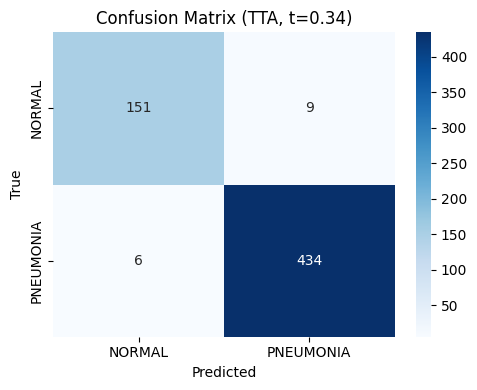

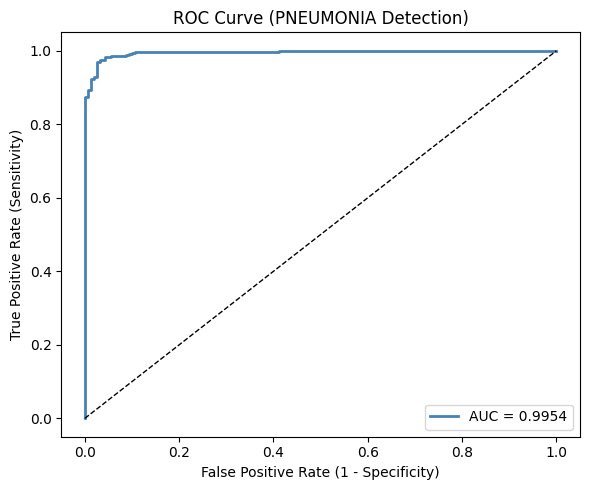

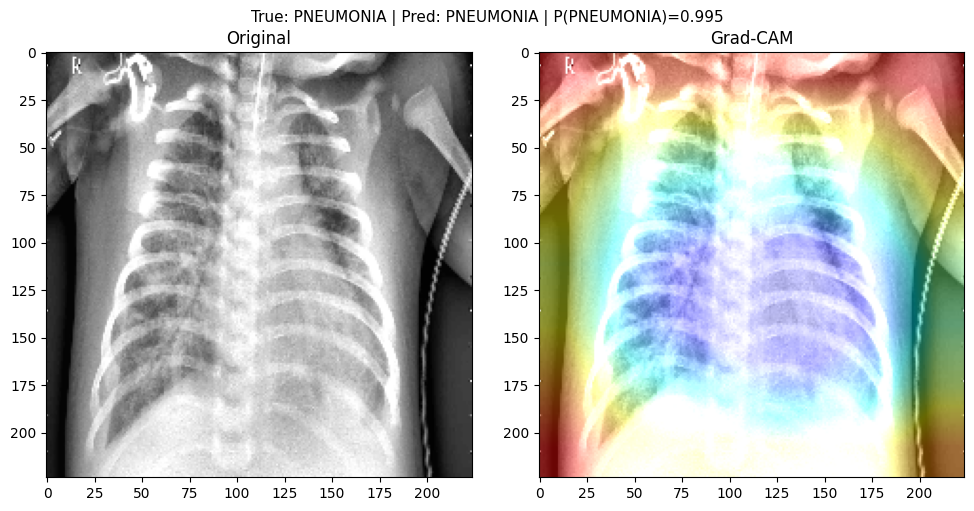

In [20]:
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,roc_auc_score, classification_report, roc_curve)


SSL_WEIGHTS = model.get_weights()
print(f"Final model: SSL (last cycle best). Lowest val_loss overall was at {GLOBAL_BEST['where']} (info only).")

tta_steps = 5
y_test_np = np.array(y_test)


print("TTA on validation set...")
val_preds = predict_tta(model, x_val, n_views=tta_steps)
v_fpr, v_tpr, v_thr = roc_curve(y_val, val_preds, pos_label=1)
j = v_tpr - v_fpr
DECISION_THRESHOLD = float(np.clip(v_thr[np.argmax(j)], 0.05, 0.95))
print(f"Validation AUC={roc_auc_score(y_val, val_preds):.4f} | Youden threshold = {DECISION_THRESHOLD:.3f}")

print("TTA on test set...")
final_preds = predict_tta(model, x_test, n_views=tta_steps)   
test_auc = roc_auc_score(y_test_np, final_preds)              


def report(threshold, name):
    pred = (final_preds >= threshold).astype(int)             
    cm = confusion_matrix(y_test_np, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    print(f"\n=== {name} (threshold = {threshold:.3f}) ===")
    print(f"TTA Accuracy          : {accuracy_score(y_test_np, pred):.4f}")
    print(f"TTA AUC (PNEUMONIA)   : {test_auc:.4f}")
    print(f"Sensitivity / Recall  : {tp / (tp + fn):.4f}")
    print(f"Specificity           : {tn / (tn + fp):.4f}")
    print(f"Precision (PPV)       : {precision_score(y_test_np, pred, pos_label=POS_LABEL):.4f}")
    print(f"NPV                   : {tn / (tn + fn) if (tn + fn) else float('nan'):.4f}")
    print(f"F1 (PNEUMONIA)        : {f1_score(y_test_np, pred, pos_label=POS_LABEL):.4f}")
    print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    return pred, cm

report(0.5, "Default threshold")


PRED_FILE = os.path.join(H5_DIR, f"preds_{PROTOCOL}_seed{GLOBAL_SEED}.npz")
np.savez(PRED_FILE, val_preds=val_preds, test_preds=final_preds, y_val=y_val, y_test=y_test_np)
print(f"Saved predictions to {PRED_FILE}")
test_preds_binary, cm = report(DECISION_THRESHOLD, "Validation-tuned threshold (reported result)")
print("\nClassification report:")
print(classification_report(y_test_np, test_preds_binary, labels=[0, 1], target_names=CLASS_NAMES, digits=4))


model.set_weights(PHASE_A_WEIGHTS)
a_val = predict_tta(model, x_val, n_views=tta_steps)
a_fpr, a_tpr, a_thr = roc_curve(y_val, a_val, pos_label=1)
a_t = float(np.clip(a_thr[np.argmax(a_tpr - a_fpr)], 0.05, 0.95))
a_test = predict_tta(model, x_test, n_views=tta_steps)
a_bin = (a_test >= a_t).astype(int)
print(f"\n[Ablation] Phase A only: acc={accuracy_score(y_test_np, a_bin):.4f}  AUC={roc_auc_score(y_test_np, a_test):.4f}  "f"sens={recall_score(y_test_np, a_bin):.4f}  spec={recall_score(y_test_np, a_bin, pos_label=0):.4f}  (t={a_t:.3f})")
model.set_weights(SSL_WEIGHTS)
del PHASE_A_WEIGHTS, a_val, a_test

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion Matrix (TTA, t={DECISION_THRESHOLD:.2f})')
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test_np, final_preds, pos_label=1)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='steelblue', lw=2, label=f'AUC = {test_auc:.4f}')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curve (PNEUMONIA Detection)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    
    base = model.layers[1] # Xception
    grad_model = tf.keras.models.Model(
        [base.inputs], [base.get_layer(last_conv_layer_name).output, base.output]
    )
    with tf.GradientTape() as tape:
        last_conv_layer_output, base_preds = grad_model(img_array)
        x = last_conv_layer_output
        for layer in model.layers[2:]:
            x = layer(x)
        preds = x
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

def display_gradcam(img_array, heatmap, alpha=0.4, title=None):
    img = np.uint8(img_array[0])   
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    superimposed_img = heatmap * alpha + img
    superimposed_img = np.clip(superimposed_img, 0, 255).astype("uint8")
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    if title:
        fig.suptitle(title, fontsize=11)
    ax[0].imshow(img)
    ax[0].set_title("Original")
    ax[1].imshow(superimposed_img)
    ax[1].set_title("Grad-CAM")
    plt.tight_layout()
    plt.show()



idx = 0
p = float(final_preds[idx])
title = f"True: {CLASS_NAMES[int(y_test_np[idx])]} | Pred: {CLASS_NAMES[int(p >= DECISION_THRESHOLD)]} | P(PNEUMONIA)={p:.3f}"
heatmap = make_gradcam_heatmap(to_model_input(x_test[idx:idx+1]), model, "block14_sepconv2_act", pred_index=0) 

display_gradcam(x_test[idx:idx+1], heatmap, title=title)

In [21]:
import json as _json
if PROTOCOL == "patient_resplit":
    MODEL_PATH = MODEL_PATH.replace("_L1PNEU.keras", "_L1PNEU_RESPLIT.keras")
print(f"Saving finalized model to {MODEL_PATH}...")
model.save(MODEL_PATH)
with open(MODEL_PATH.replace('.keras', '_labels.json'), 'w') as f:
    _json.dump({"label_map": LABEL_MAP, "class_names": CLASS_NAMES, "positive_class": "PNEUMONIA",
               "output": "sigmoid = P(PNEUMONIA)", "decision_threshold": DECISION_THRESHOLD,
               "input_scaling": "x/127.5 - 1 (Xception)", "protocol": PROTOCOL}, f, indent=2)
print("Model + label map saved successfully!")

Saving finalized model to C:\CODES__SSD512\Minor_Major_Pneumonia\Major\H5\custom_E27_CLAHE_Contrast_Xception_P4I3A3M7T4_L1PNEU_RESPLIT.keras...
Model + label map saved successfully!


In [22]:
import glob
from sklearn.metrics import accuracy_score, roc_auc_score, recall_score, roc_curve
files = sorted(glob.glob(os.path.join(H5_DIR, f"preds_{PROTOCOL}_seed*.npz")))
print("Seeds found:", [os.path.basename(f) for f in files])
if len(files) >= 2:
    runs = [np.load(f) for f in files]
    ev = np.mean([r["val_preds"] for r in runs], axis=0)
    et = np.mean([r["test_preds"] for r in runs], axis=0)
    yv, yt = runs[0]["y_val"], runs[0]["y_test"]
    f_, t_, th_ = roc_curve(yv, ev, pos_label=1)
    t_ens = float(np.clip(th_[np.argmax(t_ - f_)], 0.05, 0.95))
    for r, f in zip(runs, files):
        print(f"  {os.path.basename(f)}: test AUC={roc_auc_score(yt, r['test_preds']):.4f}")
    b = (et >= t_ens).astype(int)
    print(f"ENSEMBLE ({len(files)} seeds, t={t_ens:.3f}): acc={accuracy_score(yt, b):.4f}  AUC={roc_auc_score(yt, et):.4f}  "f"sens={recall_score(yt, b):.4f}  spec={recall_score(yt, b, pos_label=0):.4f}")
else:
    print("Need at least 2 seeds. Re-run the notebook with a different GLOBAL_SEED.")

Seeds found: ['preds_patient_resplit_seed123.npz', 'preds_patient_resplit_seed42.npz', 'preds_patient_resplit_seed7.npz']
  preds_patient_resplit_seed123.npz: test AUC=0.9954
  preds_patient_resplit_seed42.npz: test AUC=0.9936
  preds_patient_resplit_seed7.npz: test AUC=0.9950
ENSEMBLE (3 seeds, t=0.516): acc=0.9700  AUC=0.9954  sens=0.9727  spec=0.9625


### Legacy model re-check (old 0=PNEUMONIA weights, evaluated with 1=PNEUMONIA labels)

In [23]:
if PROTOCOL != "official":
    print("Legacy check skipped: under Protocol B the test split contains images the legacy model was trained on.")
else:
    legacy_model = load_model(LEGACY_MODEL_PATH, custom_objects={'AdaMed': AdaMed, 'ClassBalancedFocalLoss': ClassBalancedFocalLoss}) if os.path.exists(LEGACY_MODEL_PATH) else None
    
    if legacy_model is not None:
        legacy_p_pneu = 1.0 - predict_tta(legacy_model, x_test, n_views=tta_steps,scale_fn=lambda b: np.asarray(b, dtype='float32') / 255.0)
        legacy_bin = (legacy_p_pneu >= 0.5).astype(int)
        lcm = confusion_matrix(y_test_np, legacy_bin, labels=[0, 1])
        ltn, lfp, lfn, ltp = lcm.ravel()
        print(f"Legacy Accuracy   : {accuracy_score(y_test_np, legacy_bin):.4f}")
        print(f"Legacy AUC        : {roc_auc_score(y_test_np, legacy_p_pneu):.4f}")
        print(f"Legacy Sensitivity: {ltp/(ltp+lfn):.4f}   Specificity: {ltn/(ltn+lfp):.4f}")
        print(classification_report(y_test_np, legacy_bin, labels=[0, 1], target_names=CLASS_NAMES, digits=4))

Legacy check skipped: under Protocol B the test split contains images the legacy model was trained on.
